## Test Day with pretty ugly data

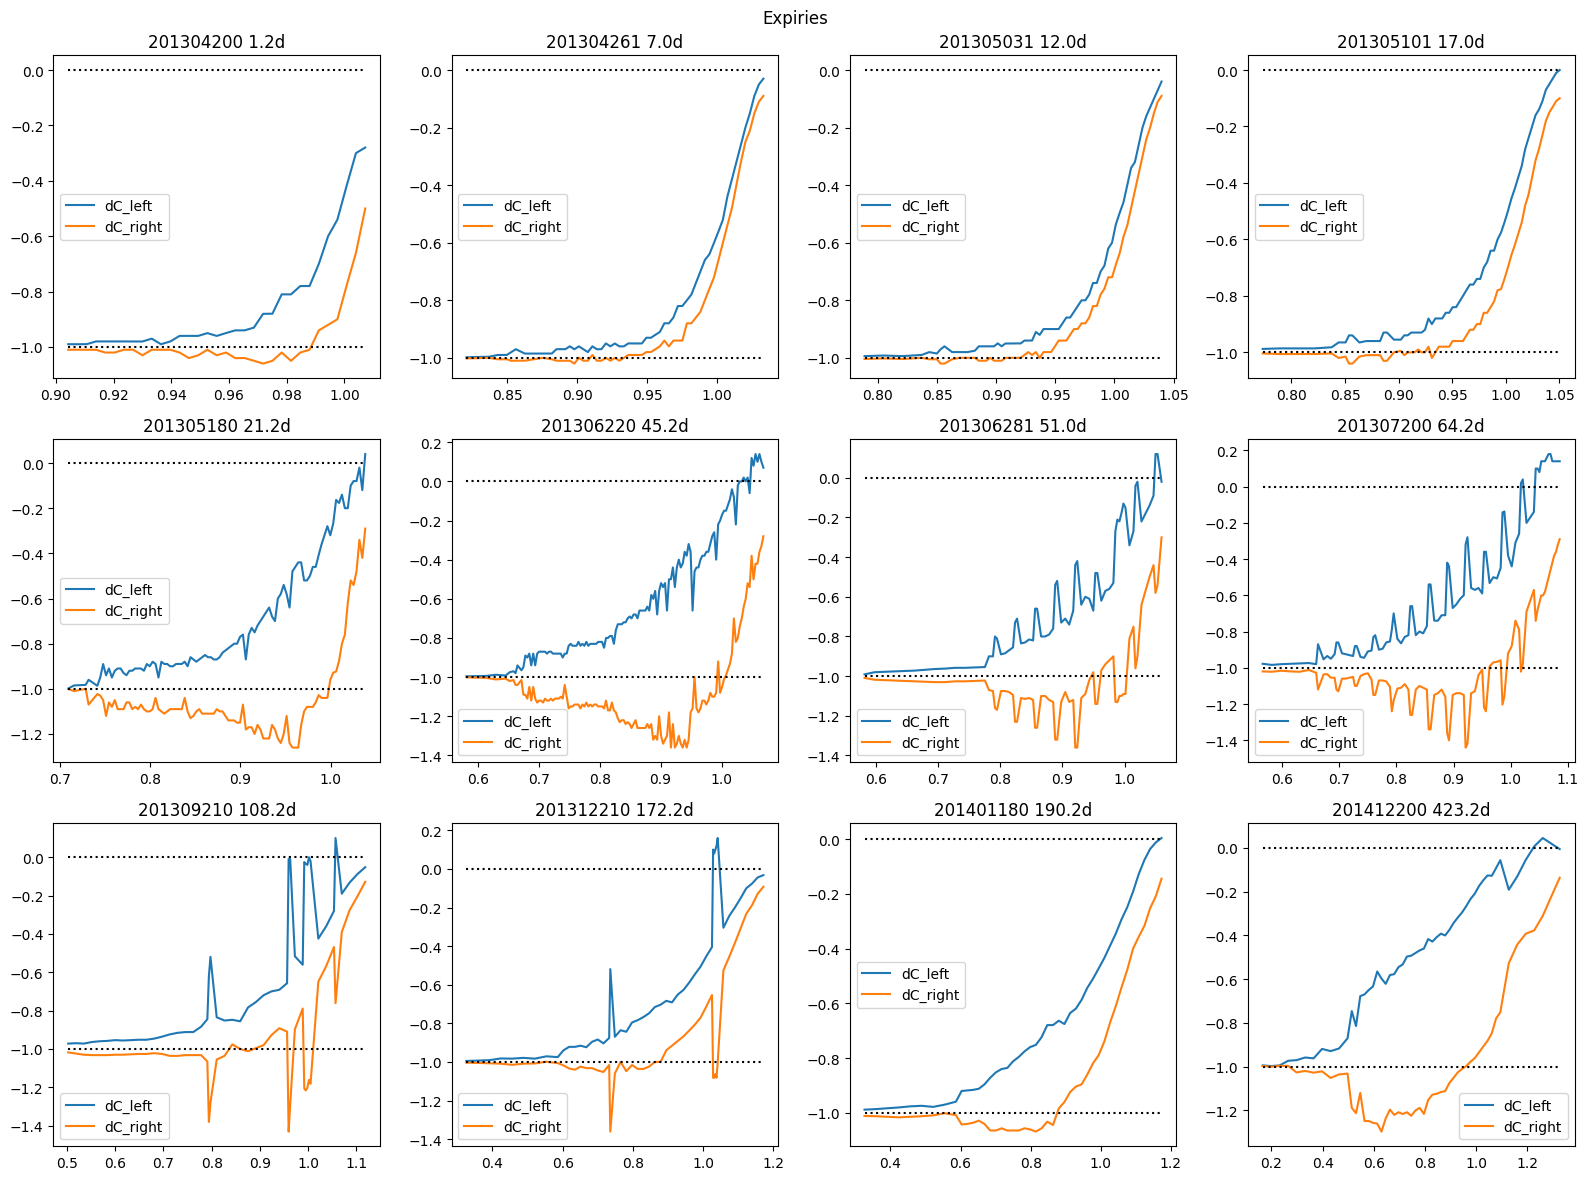

00: SPX 2013-04-17: Generating arb-free price surface.
01:   SPX 2013-04-17: Expiry #0 1.200d: generating extended strikes... removed 4 out of 34 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2013-04-17: Expiry #1 7.000d: generating extended strikes... removed 2 out of 58 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2013-04-17: Expiry #4 21.200d: generating extended strikes... removed 2 out of 98 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2013-04-17: Expiry #6 51.000d: generating extended strikes... removed 3 out of 69 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2013-04-17: Expiry #9 172.200d: generating extended strikes... removed 3 out of 51 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2013-04-17: Expiry #10 190.200d: generating extended strikes... removed 2 out of 46 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0.
01:   SPX 2013-04-17: Expiry #11 423.20d: finding linear no-arbitrage mid... cannot fi

/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/utils/arbfree.py:352: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
/home/hans/vqdata/lib/python3.12/site-packages/cvxpy/atoms/elementwise/power.py:179: RuntimeWarning: overflow encountered in power
/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/utils/arbfree.py:369: UserWarning: SPX 2013-04-17: Cannot find no-arbitrage mid for expiry 423.20d: solver hit and/or iteration limit -- removing expiry.


01:   SPX 2013-04-17: Finding arbitrage-free mid prices accross the entire surface of 484 strikes with a minimum strike distance of 0.00322... done. This took 0.35s.
00: SPX 2013-04-17: generated arbitrage-free price surface. Dropped 1 expiries and 294 strikes of the remaining expiries. This took 0.76s.


,spot,spot_prev,date,ticker,call_symbol,put_symbol,call_opt_id,put_opt_id,is_american,is_am,...,pure_fit1_delta,pure_fit1_dk,pure_fit1_gamma,pure_fit1_vega,pure_fit1_theta,pure_fitX_delta,pure_fitX_dk,pure_fitX_gamma,pure_fitX_vega,pure_fitX_theta
0,1552.01001,1574.569946,2013-04-17,SPX,SPX 130420C1400000,SPX 130420P1400000,100251840,100251892,False,True,...,0.997379,-0.997058,0.215525,0.000559,0.031970,0.998522,-0.998343,0.136515,0.000332,0.017837
1,1552.01001,1574.569946,2013-04-17,SPX,SPX 130420C1405000,SPX 130420P1405000,100435064,100435114,False,True,...,0.996787,-0.996406,0.261694,0.000672,0.038005,0.998133,-0.997914,0.170565,0.000411,0.021843
2,1552.01001,1574.569946,2013-04-17,SPX,SPX 130420C1410000,SPX 130420P1410000,100313941,100313967,False,True,...,0.996176,-0.995738,0.310382,0.000785,0.043797,0.997723,-0.997465,0.207091,0.000492,0.025788
3,1552.01001,1574.569946,2013-04-17,SPX,SPX 130420C1415000,SPX 130420P1415000,100435065,100435115,False,True,...,0.995544,-0.995051,0.362197,0.000900,0.049351,0.997220,-0.996915,0.251604,0.000590,0.030458
4,1552.01001,1574.569946,2013-04-17,SPX,SPX 130420C1420000,SPX 130420P1420000,100295353,100295382,False,True,...,0.994887,-0.994342,0.417808,0.001018,0.054676,0.996617,-0.996261,0.304684,0.000703,0.035804
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
751,1552.01001,1574.569946,2013-04-17,SPX,SPX 140118C1700000,SPX 140118P1700000,82865712,82865765,False,True,...,0.200456,-0.169921,2.448745,0.243556,0.021262,0.200456,-0.169921,2.448745,0.243556,0.021262
752,1552.01001,1574.569946,2013-04-17,SPX,SPX 140118C1725000,SPX 140118P1725000,100307728,100307732,False,True,...,0.160014,-0.134341,2.178275,0.211394,0.018006,0.160014,-0.134341,2.178275,0.211394,0.018006
753,1552.01001,1574.569946,2013-04-17,SPX,SPX 140118C1750000,SPX 140118P1750000,100307729,100307733,False,True,...,0.126410,-0.105026,1.887876,0.180244,0.015104,0.126410,-0.105026,1.887876,0.180244,0.015104
754,1552.01001,1574.569946,2013-04-17,SPX,SPX 140118C1775000,SPX 140118P1775000,100307730,100307734,False,True,...,0.098184,-0.080705,1.597770,0.150438,0.012432,0.098184,-0.080705,1.597770,0.150438,0.012432


In [1]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2013, 4, 17), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad=False)

    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad=False)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )
    with figure("Expiries", row_size=4, col_size=4, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]
            ax = fig.add_subplot(f"{uid} {tte_y*DAYS_PER_YEAR:.1f}d")

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()

            dC_left = ( asks[1:] - bids[:-1] ) / ( strikes[1:] - strikes[:-1] )
            dC_right = ( asks[:-1] - bids[1:] ) / ( strikes[:-1] - strikes[1:] )

            ax.plot(strikes[1:], dC_left, label="dC_left")
            ax.plot(strikes[1:], dC_right, label="dC_right")
            ax.plot(strikes[1:], strikes[1:]*0-1., ":", color="black")
            ax.plot(strikes[1:], strikes[1:]*0, ":", color="black")
            ax.legend()

    arb_free = MkArbFree(cvxpy_solver_options={"time_limit":1})
    arb_free = mk_arb_free_day(ticker, d, enr_day, mk_arb_free=arb_free, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad=False, override_cache_mode="off")

    display(arb_free)
    return arb_free

_ = test()